In [1]:
# ============================================================
#  فایل آموزش مدل واقعی: train_fuel_real_model.ipynb
#  وظیفه: آموزش رگرسیون خطی روی داده‌های واقعی (با نویز)،
#         ارزیابی مدل با R² و RMSE، ذخیره مدل و رسم نمودار
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

In [2]:
# ---------- ۱. تعریف داده‌های واقعی (با نویز) ----------
# مسافت (کیلومتر)
X = np.array([[100], [200], [300], [400],
              [500], [600], [700], [800]])

# مصرف بنزین (لیتر) — دیگر دقیقاً خطی نیست
y = np.array([9.5, 15.0, 26.5, 31.0,
              42.0, 47.5, 58.0, 62.5])

In [3]:
# ---------- ۲. ساخت و آموزش مدل ----------
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.08]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.143
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[648.07]


In [4]:
# ---------- ۳. استخراج پارامترهای مدل ----------
a = model.coef_[0]
b = model.intercept_

print("=" * 55)
print("نتایج آموزش مدل (داده واقعی با نویز)")
print("=" * 55)
print(f"شیب (a): {a:.4f}")
print(f"عرض از مبدأ (b): {b:.4f}")
print(f"معادله: مصرف = {a:.4f} × مسافت + {b:.4f}")
print("=" * 55)

نتایج آموزش مدل (داده واقعی با نویز)
شیب (a): 0.0786
عرض از مبدأ (b): 1.1429
معادله: مصرف = 0.0786 × مسافت + 1.1429


In [5]:
# ---------- ۴. ارزیابی مدل ----------
y_pred = model.predict(X)

mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("معیارهای ارزیابی مدل")
print("-" * 55)
print(f"MSE  (میانگین مربعات خطا):     {mse:.4f}")
print(f"RMSE (ریشه میانگین مربعات خطا): {rmse:.4f} لیتر")
print(f"MAE  (میانگین قدر مطلق خطا):   {mae:.4f} لیتر")
print(f"R²   (ضریب تعیین):              {r2:.4f}")
print("=" * 55)

معیارهای ارزیابی مدل
-------------------------------------------------------
MSE  (میانگین مربعات خطا):     2.2679
RMSE (ریشه میانگین مربعات خطا): 1.5059 لیتر
MAE  (میانگین قدر مطلق خطا):   1.4286 لیتر
R²   (ضریب تعیین):              0.9931


In [6]:
# ---------- ۵. نمایش خطاهای هر نقطه ----------
print("خطاهای هر نقطه (واقعی - پیش‌بینی):")
print("-" * 55)
for i in range(len(X)):
    error = y[i] - y_pred[i]
    print(f"مسافت {X[i][0]:>4} km | واقعی: {y[i]:>5.1f} | "
          f"پیش‌بینی: {y_pred[i]:>6.2f} | خطا: {error:>+6.2f}")
print("=" * 55)

خطاهای هر نقطه (واقعی - پیش‌بینی):
-------------------------------------------------------
مسافت  100 km | واقعی:   9.5 | پیش‌بینی:   9.00 | خطا:  +0.50
مسافت  200 km | واقعی:  15.0 | پیش‌بینی:  16.86 | خطا:  -1.86
مسافت  300 km | واقعی:  26.5 | پیش‌بینی:  24.71 | خطا:  +1.79
مسافت  400 km | واقعی:  31.0 | پیش‌بینی:  32.57 | خطا:  -1.57
مسافت  500 km | واقعی:  42.0 | پیش‌بینی:  40.43 | خطا:  +1.57
مسافت  600 km | واقعی:  47.5 | پیش‌بینی:  48.29 | خطا:  -0.79
مسافت  700 km | واقعی:  58.0 | پیش‌بینی:  56.14 | خطا:  +1.86
مسافت  800 km | واقعی:  62.5 | پیش‌بینی:  64.00 | خطا:  -1.50


In [8]:
# ---------- ۶. ذخیره مدل ----------
MODEL_PATH = "model/fuel_real_model.pkl"
joblib.dump(model, MODEL_PATH)
print(f"مدل با موفقیت در فایل «{MODEL_PATH}» ذخیره شد.")

مدل با موفقیت در فایل «model/fuel_real_model.pkl» ذخیره شد.


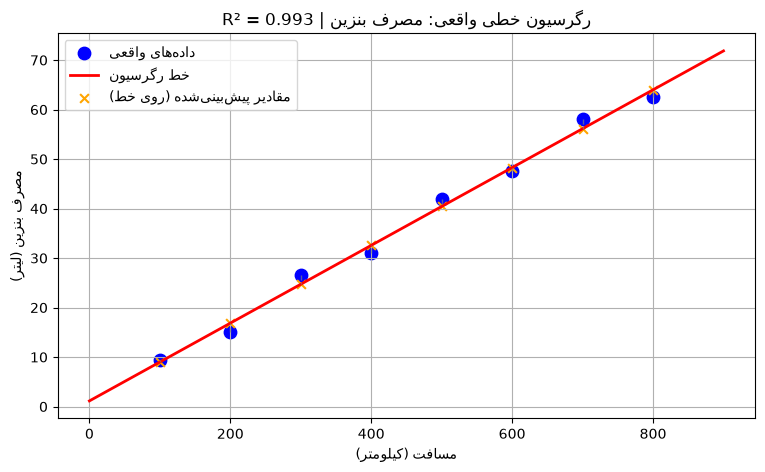

In [10]:
# ---------- ۷. رسم نمودار با نمایش خطاها ----------
plt.figure(figsize=(9, 5))

# نقاط داده واقعی
plt.scatter(X, y, color='blue', s=80, label='داده‌های واقعی')

# خط رگرسیون
X_line = np.linspace(0, 900, 100).reshape(-1, 1)
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label='خط رگرسیون')

# رسم خطای هر نقطه (خطوط عمودی از نقطه تا خط)
for i in range(len(X)):
    plt.plot([X[i][0], X[i][0]], [y[i], y_pred[i]],
             color='gray', linestyle='--', linewidth=1, alpha=0.7)

# نقاط پیش‌بینی‌شده روی خط
plt.scatter(X, y_pred, color='orange', s=40, marker='x',
            label='مقادیر پیش‌بینی‌شده (روی خط)')

plt.xlabel('مسافت (کیلومتر)')
plt.ylabel('مصرف بنزین (لیتر)')
plt.title(f'رگرسیون خطی واقعی: مصرف بنزین | R² = {r2:.3f}')
plt.legend()
plt.grid(True)
fig = plt.gcf()

In [11]:
# ذخیره نمودار (قبل از show)
PLOT_PATH = "results/fuel_real_regression_plot.png"
fig.savefig(PLOT_PATH, dpi=150, bbox_inches='tight')
print(f"نمودار در فایل «{PLOT_PATH}» ذخیره شد.")

plt.show()

نمودار در فایل «results/fuel_real_regression_plot.png» ذخیره شد.
